# SEM.9.10 — Notebook 2: The Jones loop correction for unsteady flow

Reproducibility notebook for **SFFS technical report SEM.9.10, *The Dynamic Rating at Bweramule: a Stage–Discharge Relation that Moves with the River*** (Ministry of Water and Environment, Uganda, 2026), Sections 4.4 and 5.5.

On a rising river the flow at a given stage is larger than on a steady one, and on a falling river smaller. The Jones formula corrects a steady rating for the rate of stage change:

$$Q = Q_{steady}(h)\,\sqrt{1 + \frac{\partial h/\partial t}{S_0\,c}},\qquad c = \frac{1}{B}\frac{dQ}{dh},$$

with $S_0$ the bed slope, $B$ the top width and $c$ the kinematic-wave celerity. In the report $S_0$ = 0.00034 (from the hydraulic model inverts) and $B$ = 107 m (ADCP section of 9 March 2025); the rate is capped at ±1 m/day, faster changes being treated as sensor events. The rating below is illustrative; the formula and parameters are those of the report.

dh/dt -0.40 m/day: Jones factor 0.9950 (-0.5 %)
dh/dt -0.20 m/day: Jones factor 0.9975 (-0.3 %)
dh/dt +0.00 m/day: Jones factor 1.0000 (+0.0 %)
dh/dt +0.20 m/day: Jones factor 1.0025 (+0.3 %)
dh/dt +0.39 m/day: Jones factor 1.0049 (+0.5 %)
dh/dt +0.60 m/day: Jones factor 1.0075 (+0.8 %)
dh/dt +1.00 m/day: Jones factor 1.0125 (+1.3 %)


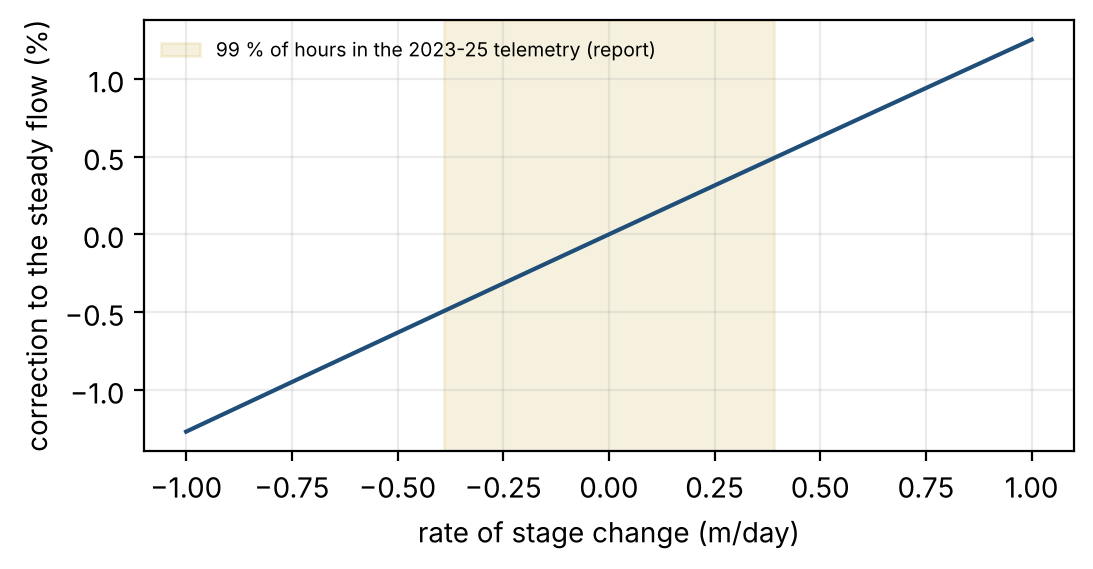

In [1]:
import os, sys, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import semliki_dynrating as D
S0, WIDTH = 0.00034, 107.0
q_of_h, h_of_q, _ = D.power_rating(9.0, 8.0, 2.5)          # illustrative rating
bh = np.linspace(8.05, 16, 400); R = D.Rating(bh, q_of_h(bh), 0.0, 0.05)
h = float(h_of_q(200.0))
for r in (-0.4, -0.2, 0.0, 0.2, 0.39, 0.6, 1.0):
    q, lo, hi, f = R.flow(h, r, S0, WIDTH)
    print("dh/dt %+.2f m/day: Jones factor %.4f (%+.1f %%)" % (r, f, 100 * (f - 1)))
rates = np.linspace(-1, 1, 81)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(rates, [100 * (D.jones(R, h, x, S0, WIDTH) - 1) for x in rates], color="#1F4E79")
ax.axvspan(-0.39, 0.39, color="#C9A227", alpha=.15, label="99 % of hours in the 2023-25 telemetry (report)")
ax.set_xlabel("rate of stage change (m/day)"); ax.set_ylabel("correction to the steady flow (%)"); ax.grid(alpha=.25); ax.legend(fontsize=7, frameon=False)
plt.show()